### TEL354 - Minería de datos
# Clase 7: Regression
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

## ¿Cuándo usar regresión?

Usamos regresión cuando la variable objetivo es numérica.

### Ejemplos:

- precio de casas
- temperatura
- ingresos

Si la salida es categórica → usamos clasificación

In [1]:
from Clase7 import *

# Regresión

Se utiliza para comprender y predecir cómo cambia una variable dependiente en función de una o más variables independientes. Puede ser útil para identificar patrones, tendencias o relaciones en los datos, así como para hacer predicciones sobre valores futuros o desconocidos de la variable dependiente.

<div align="center">
<img src="img/var_ind_dep.jpg" alt="" width="50%" align="center" />
</div>


# Regresión lineal 

Suponen una relación lineal entre las variables, donde se ajusta una línea (en el caso de la regresión simple) o un plano hiperplano (en el caso de la regresión múltiple) a los datos.

<div align="center">
<img src="img/reg_lin.png" alt="" width="30%" align="center" />
</div>

## Regresión lineal simple

La forma más básica de la regresión lineal se conoce como regresión lineal simple, donde hay una única variable independiente ($x$) que se utiliza para predecir la variable dependiente ($y$). La ecuación de la recta se expresa de la forma $y = mx + b$, donde $m$ es la pendiente y $b$ el intercepto.

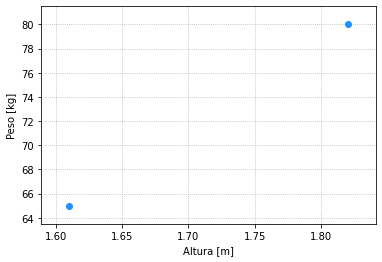

In [2]:
linear_regression(x_coord=[1.61,1.82], y_coord=[65,80], reg=False, x_test=None, x_label="Altura [m]", y_label="Peso [kg]")

## ¿Qué hace realmente la regresión?

Busca aprender una función que relacione entradas (X) con una salida (y).

No solo ajusta una línea… está aproximando una función desconocida.

Ejemplo:

horas de estudio → nota

Objetivo: predecir valores nuevos.

## ¿Cómo encontrar esa función?

**Mínimos cuadrados:** Minimizando la suma de los cuadrados de las diferencias entre los valores reales y los valores predichos por el modelo, lo que se conoce como el método de mínimos cuadrados.

In [3]:
d = {'estudio': [29, 5, 12, 36, 16, 25, 50, 10, 30, 33, 43, 2, 39, 18, 46, 27, 41, 15, 22, 50],
     'nota':    [65, 7, 8,  76, 23, 56, 100, 3, 74, 48, 73, 0, 62, 37, 74, 40, 90, 42, 58, 100]}

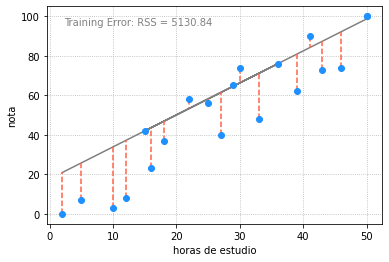

In [4]:
least_squares(d['estudio'], d['nota'], x_label="horas de estudio", y_label="nota")

## Función de costo

La función de costo o pérdida es una medida de la discrepancia entre los valores predichos por el modelo y los valores reales observados en los datos. En la regresión lineal ordinaria (también conocida como mínimos cuadrados ordinarios), la función de costo más comúnmente utilizada es la suma de los cuadrados de las diferencias entre los valores predichos y los valores reales. Esta función de costo se llama "error cuadrático medio" (MSE, por sus siglas en inglés) y se define como:

$$ \text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $$


<div style="background-color:#d4edda; border-left:6px solid #28a745; padding:10px;">

**Objetivo:** encontrar los coeficientes que minimicen esta función de costo, lo que significa que el modelo se ajustará mejor a los datos.

</div>

## ¿Por qué usamos error cuadrático?

Medimos qué tan lejos estamos del valor real.

### ¿Por qué al cuadrado?

Queremos castigar fuertemente malas predicciones

- penaliza errores grandes
- evita cancelaciones (positivos/negativos)



# The Gradient Descent Algorithm

El algoritmo de descenso de gradiente (Gradient Descent Algorithm) es un método de optimización utilizado para encontrar el mínimo de una función según: $P_{n+1} = P_{n} - \gamma \nabla J(P_{n})$


In [5]:
x_poly = np.linspace(-4,4,100)
y_poly = cost_function(x_poly)

In [6]:
plot_gradient_descent(x_coord=x_poly, y_coord=y_poly)

interactive(children=(IntSlider(value=0, description='Step', max=10), FloatSlider(value=0.25, description='Lea…

# Limitaciones de la regresión lineal

No siempre va a ser posible ajustar los datos con una línea recta:

In [7]:
cx = np.array([1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22])
cy = np.array([100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100])
pendiente, intercepto, r, p, std_err = stats.linregress(cx, cy)
recta = pendiente * cx + intercepto 

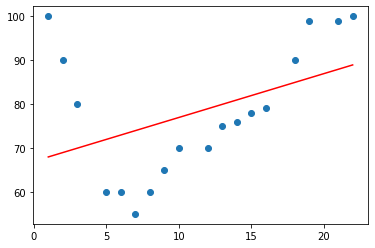

In [8]:
plt.scatter(cx, cy)
plt.plot(cx, recta, c="r")
plt.show()

# Regresión polinomial

En lugar de ajustar una línea recta a los datos, la regresión polinomial utiliza una función polinomial de grado $n$ para ajustarse a los datos, lo que permite capturar relaciones no lineales más complejas.

$$ y = b_0 + b_1x + b_2x^2 + \ldots + b_nx^n $$


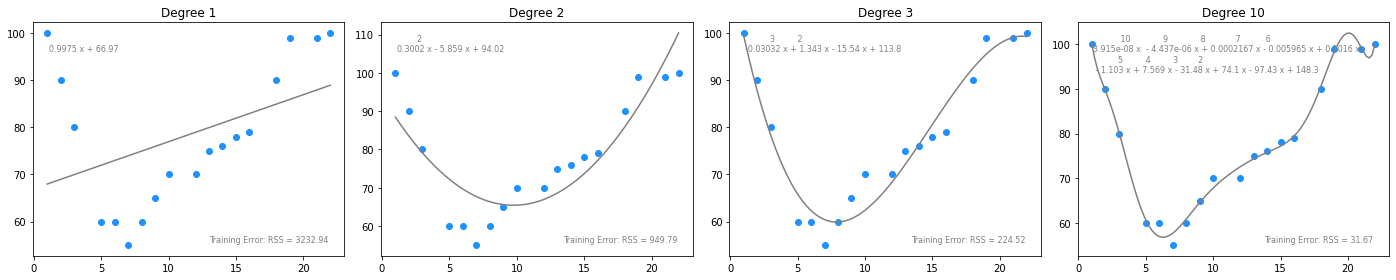

In [9]:
plot_polynomial_regression(cx, cy, list_of_degrees=[1, 2, 3, 10])

# Overfitting vs Underfitting

<div align="center">
<img src="img/fitting.jpg" alt="" width="80%" align="center" />
</div>

## ¿Por qué regularizar?

Un modelo muy complejo puede ajustarse demasiado a los datos (overfitting)

**Idea clave:** penalizamos modelos "complicados"

Preferimos:

- coeficientes pequeños
- modelos más simples

# Regularización

El proceso de regularización es una técnica utilizada para evitar el sobreajuste (overfitting) del modelo a los datos de entrenamiento. Durante el ajuste, los coeficientes se eligen de manera que minimicen la función de costo. La regularización introduce una penalización en la función de costo para desalentar la aparición de coeficientes de gran magnitud, lo que ayuda a controlar la complejidad del modelo y mejorar su capacidad de generalización a nuevos datos.

$$ Ridge = \sum_{i=1}^{n} (y_i - \hat{y_i})^2 + \lambda \sum_{j=1}^p b_j^2 $$

$$ Lasso = \sum_{i=1}^{n} (y_i - \hat{y_i})^2 + \lambda \sum_{j=1}^p | b_j | $$

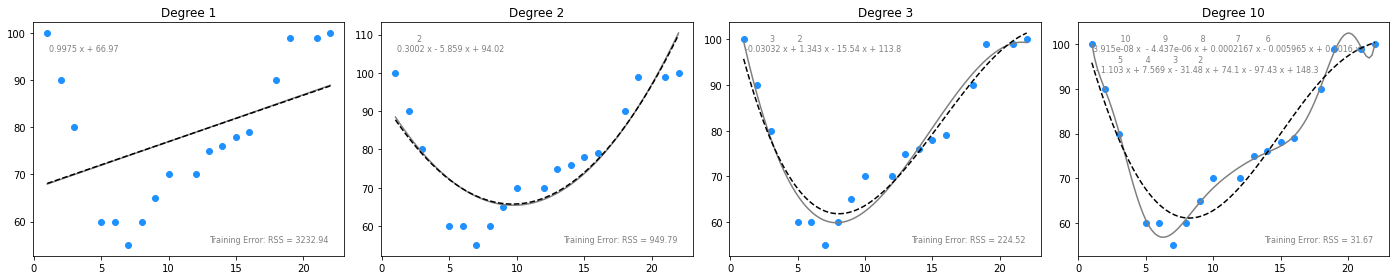

In [10]:
plot_polynomial_regression(cx, cy, list_of_degrees=[1, 2, 3, 10], regularizer='lasso', alpha=0.5)

## Ridge vs Lasso

Ridge (L2)→ suaviza

- reduce coeficientes
- pero NO los elimina

Lasso (L1)→ simplifica

- puede llevar coeficientes a 0
- hace selección de variables

# Regresión Lineal para estimar el precio de una casa en California

In [11]:
from sklearn.datasets import fetch_california_housing

X, y = fetch_california_housing(as_frame=True, return_X_y=True)

In [12]:
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [13]:
# La variable objetivo es el valor medio de la vivienda expresada en USD $100,000.
y

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

# Train-Test-Split

<div align="center">
<img src="img/train-test-split.png" alt="" width="80%" align="center" />
</div>

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=29)

# Training

In [15]:
from sklearn.linear_model import RidgeCV
model = RidgeCV().fit(X_train, y_train)

# Testing

Métricas de evaluación para regresión (valor numérico):

$$\mathbf{MAE} = \frac{\sum_{i=1}^n |\hat{y_i}-y_i|}{n}$$

$$\mathbf{MSE} = \frac{\sum_{i=1}^n (\hat{y_i}-y_i)^2}{n}$$

In [16]:
y_pred = model.predict(X_test)
print("MAE = {0:.2f}".format(mean_absolute_error(y_test, y_pred)))

MAE = 0.53


In [17]:
print("Hay un error de USD ${0:.0f}".format(100000*mean_absolute_error(y_test, y_pred)))

Hay un error de USD $52958


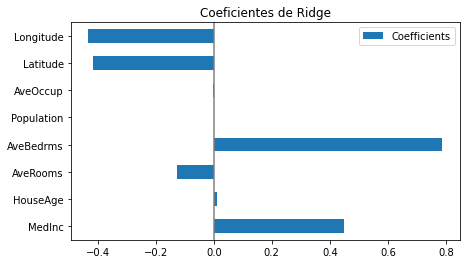

In [18]:
coefs = pd.DataFrame(
   model.coef_,
   columns=['Coefficients'], index=X_train.columns
)
coefs.plot(kind='barh', figsize=(9, 4))
plt.title('Coeficientes de Ridge')
plt.axvline(x=0, color='.5')
plt.subplots_adjust(left=.3)

## ¿Cómo interpretar los coeficientes?

Cada coeficiente indica cuánto cambia la predicción si cambia esa variable


### Ejemplo:

si coef = 2,

aumentar 1 unidad en X  → aumenta 2 unidades en y

Signo importa:

- positivo → relación directa
- negativo → relación inversa

# Aplicación de Regresión Lineal para Completación de Rostros

In [19]:
from sklearn.datasets import fetch_olivetti_faces

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import RidgeCV
from random import sample

In [21]:
data, targets = fetch_olivetti_faces(return_X_y=True)

In [22]:
data.shape, targets.shape

((400, 4096), (400,))

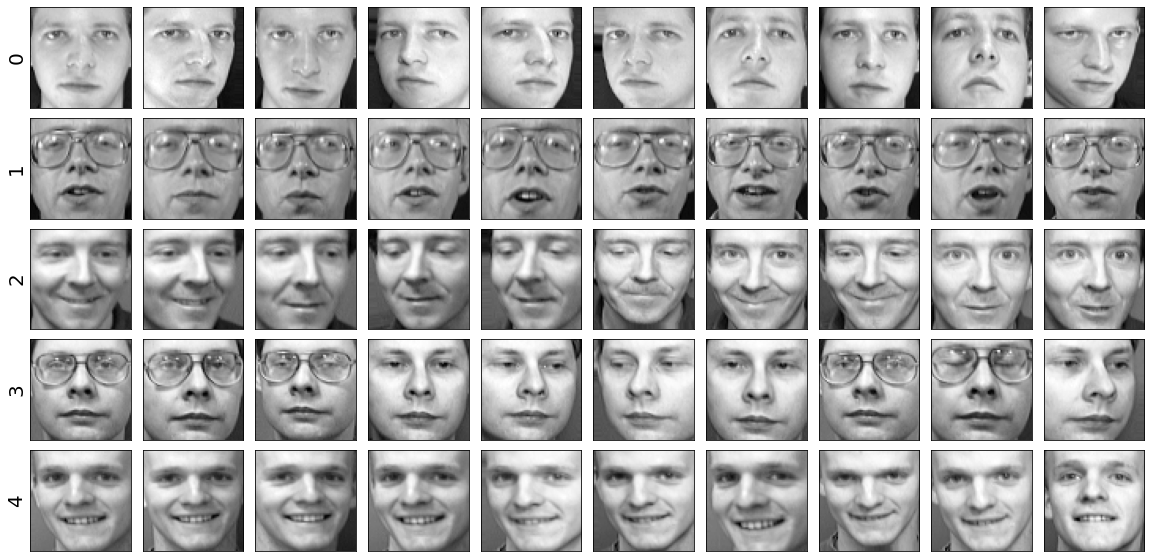

In [23]:
plot_faces(data, targets, n_person = 5, n_faces = 10)

# Separación de datos Train-Test

In [24]:
train = data[targets < 30] # Se va a entrenar con 30 personas (300 imagenes)
test = data[targets >= 30] # Se dejan 10 personas para pruebas (100 imagenes)

In [25]:
train.shape, test.shape

((300, 4096), (100, 4096))

# Se corta la mitad inferior

In [26]:
n_pixels = data.shape[1]

X_train = train[:, : (n_pixels + 1) // 2]
y_train = train[:, n_pixels // 2 :]

X_test = test[:, : (n_pixels + 1) // 2]
y_test = test[:, n_pixels // 2 :]

# En resumen...

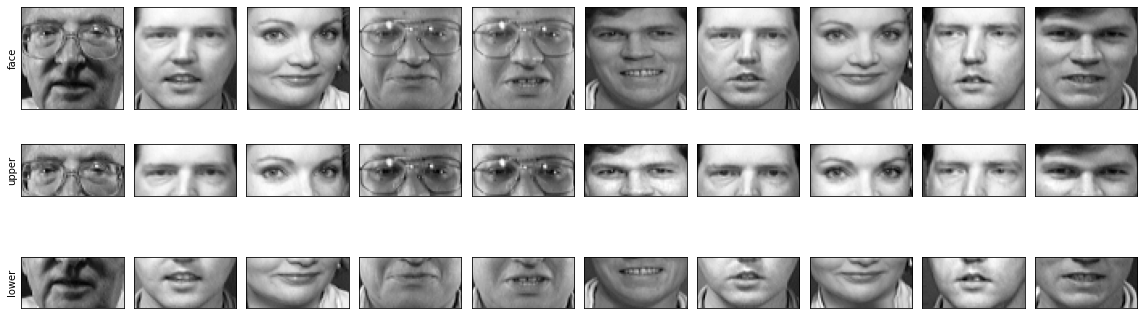

In [27]:
plot_test_faces(test, X_test, y_test, n_faces = 10)

# Entrenamiento

Se entrena con los datos de entrenamiento usando los modelos de regresión lineal simple (sin regularizar) y la forma regularizada con Ridge Regression.

In [28]:
lr = LinearRegression().fit(X_train, y_train)

In [29]:
ridge = RidgeCV().fit(X_train, y_train)

# Predicción

Se predice con los datos de prueba usando los modelos ya entrenados.

In [30]:
lr_predict = lr.predict(X_test)
ridge_predict = ridge.predict(X_test)

# Visualizar predicciones

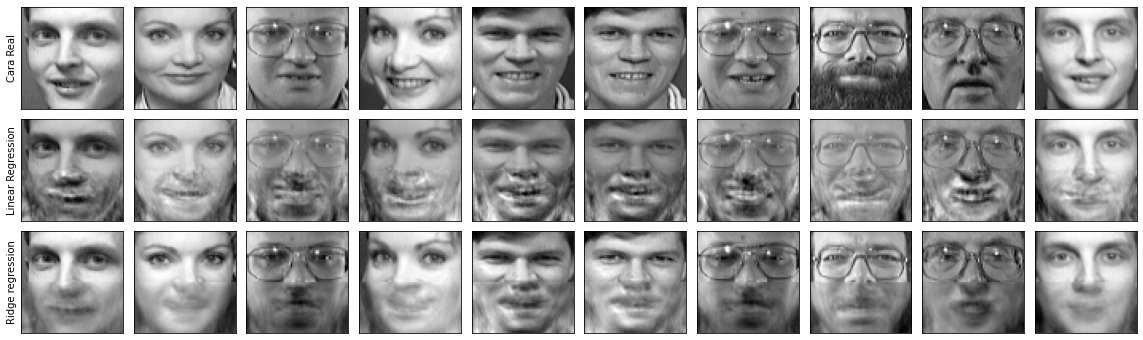

In [31]:
plot_predicted_faces(X_test, y_test, lr_predict, ridge_predict, n_faces = 10)